In [3]:
import numpy as np
import matplotlib.pyplot as plt
import csv
import os 
import scipy
from scipy.optimize import curve_fit

In [5]:
def plotStandards(xlabel , ylabel):
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tick_params(axis='both', which='both', direction='in', right=True , labelright=True)
    plt.minorticks_on()
    plt.grid(True)
    plt.legend()


In [7]:
def loadnsave( filePath ):
    data1 = []
    data2 = []
    data3=  []
    with open(filePath) as csvDataFile:
        csvReader = csv.reader(csvDataFile)
        next(csvReader)# I don't think there is a preamble, I was wrong, it contains the column and row numbers
        for row in csvReader:
            data1.append( float(row[1]))
            data2.append(float(row[2]))
            data3.append(float(row[3]))
    return np.array(data1) , np.array(data2) , np.array(data3)
# first column time second column, then stage temp, then sample temp

time , stageTemp , sampleTemp = loadnsave(r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\data\414\4-14_equilibrium5VheaterCoil_19c.csv')


In [9]:

def plotFile( *args ):
    filePath = args[0]
    tempTime , tempStage , tempSample = loadnsave(filePath)
    fig = plt.figure()
    ax = fig.add_subplot()

    if len(args)>1:
        plt.plot( tempTime[args[1]:args[2]] , tempStage[args[1]:args[2]] , "b." , label="Stage Temperature")
        plt.plot( tempTime[args[1]:args[2]] , tempSample[args[1]:args[2]] , "r." , label="Sample Temperature")
        plt.title(filePath.split("datalist")[1][1:]   )
        plotStandards("Time (s)" , "Temperature (c)" )
    else:
        plt.plot( tempTime , tempStage , "b." , label="Stage Temperature")
        plt.plot( tempTime , tempSample , "r." , label="Sample Temperature")
        plt.title(filePath.split("datalist")[1][1:]   )
        plotStandards("Time (s)" , "Temperature (c)" )

#Single File test, will be used with directory list "listdir"
    
#plotFile(r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\datalist\4-14_equilibrium5VheaterCoil_19c.csv')

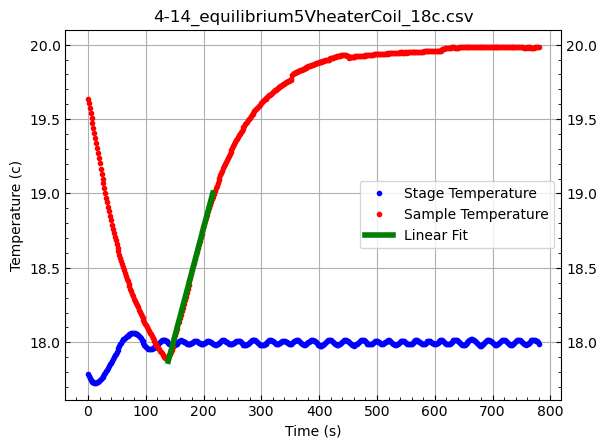

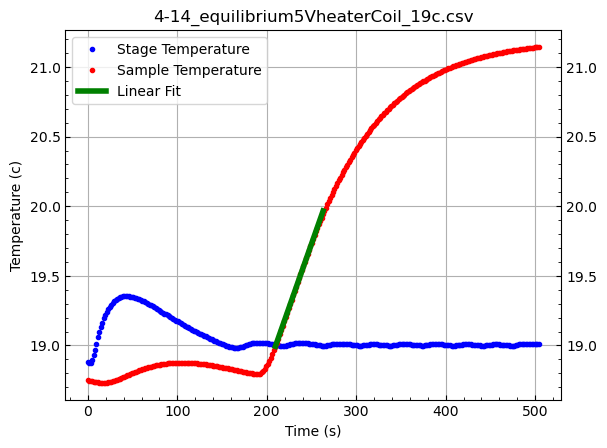

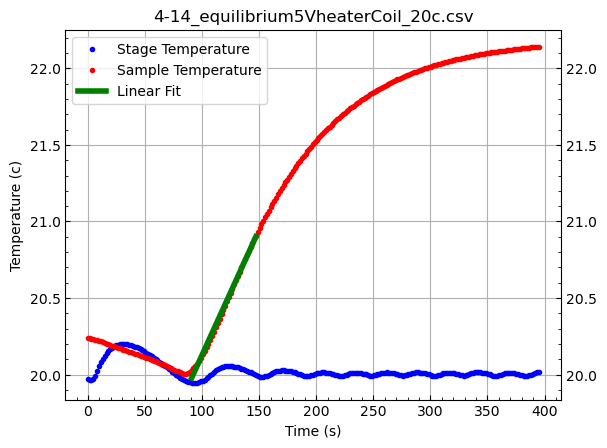

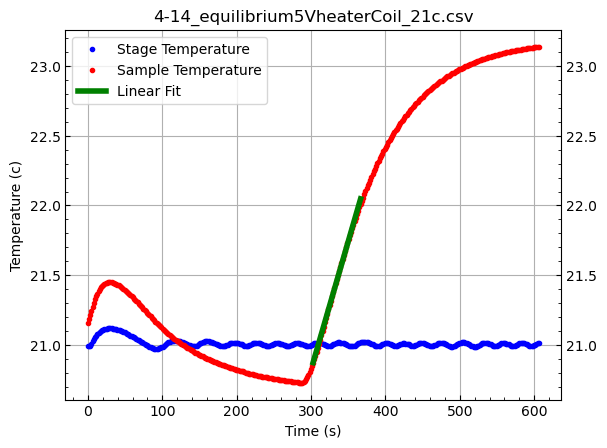

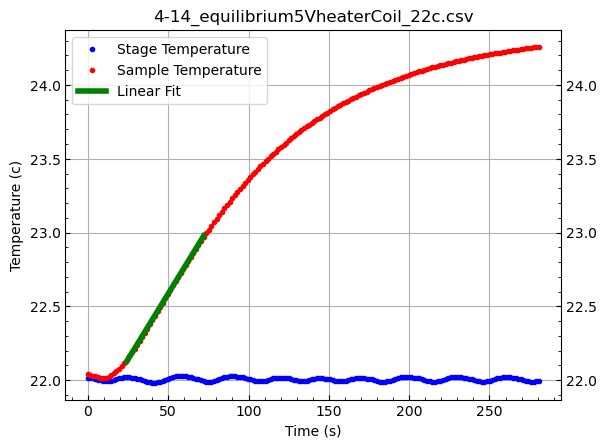

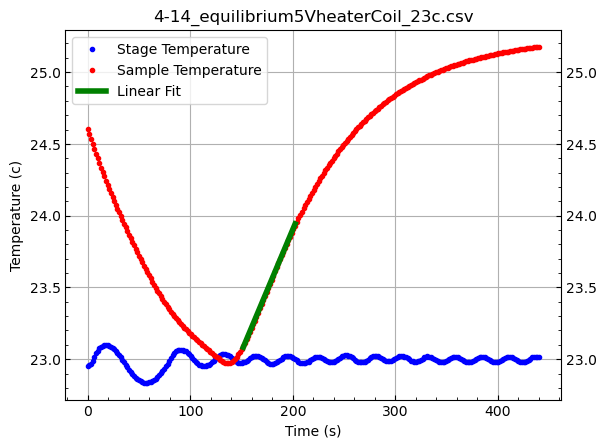

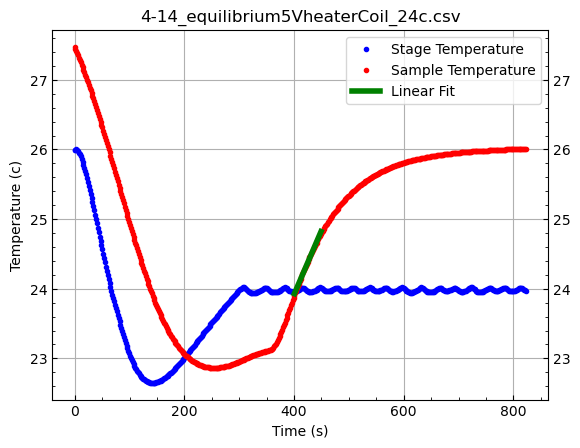

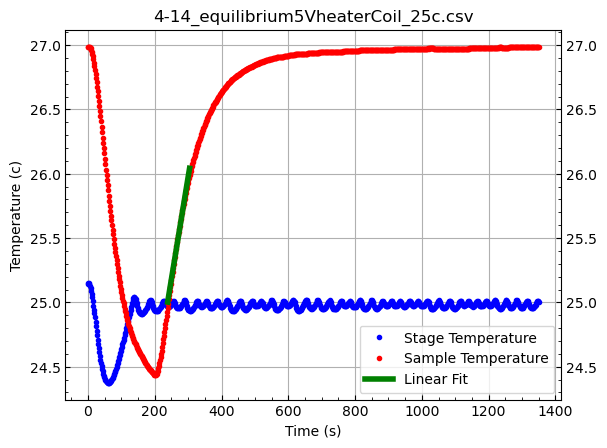

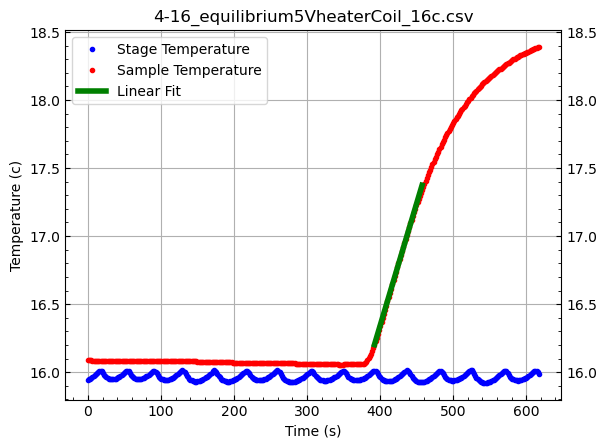

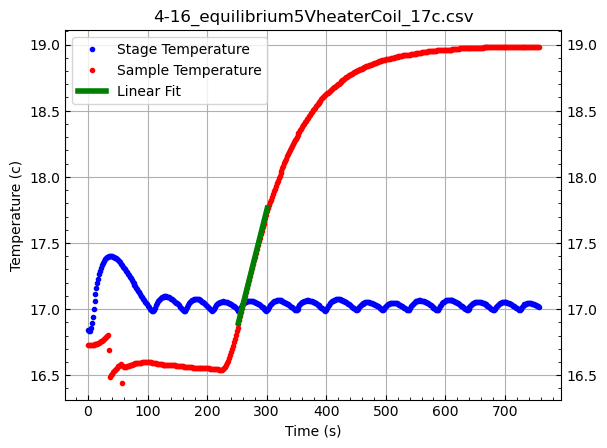

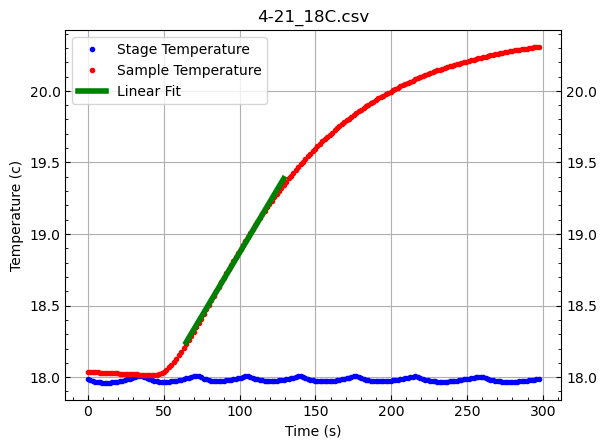

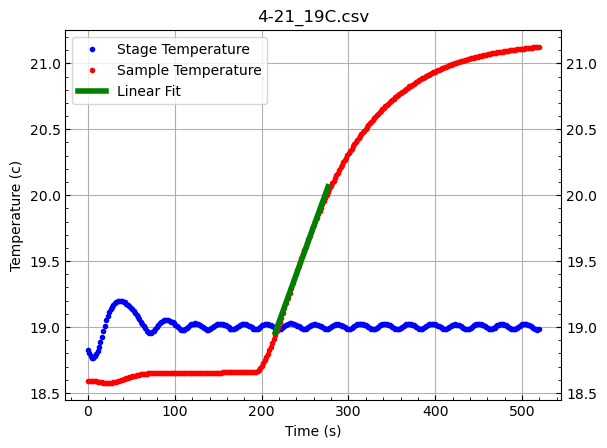

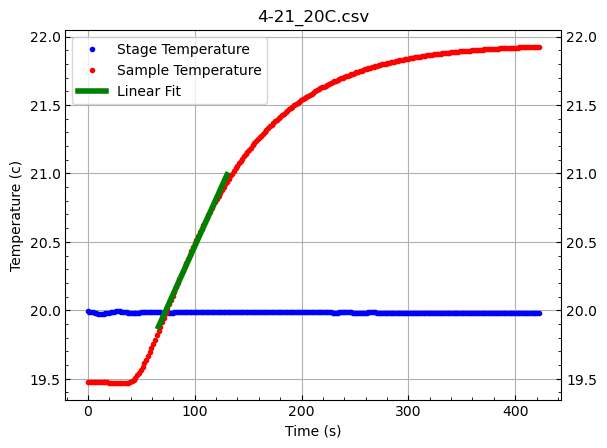

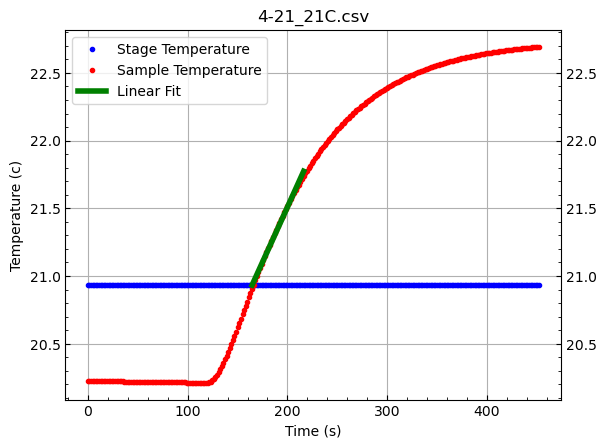

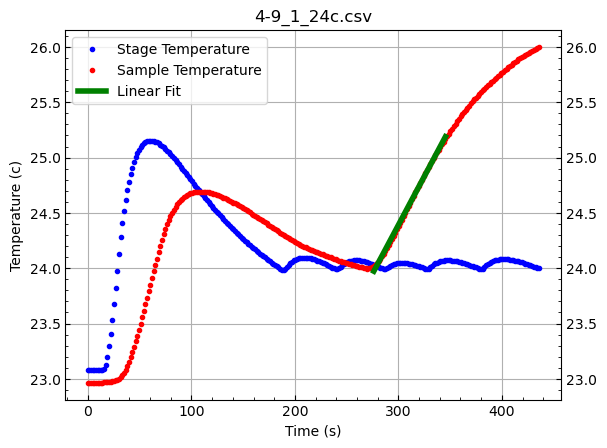

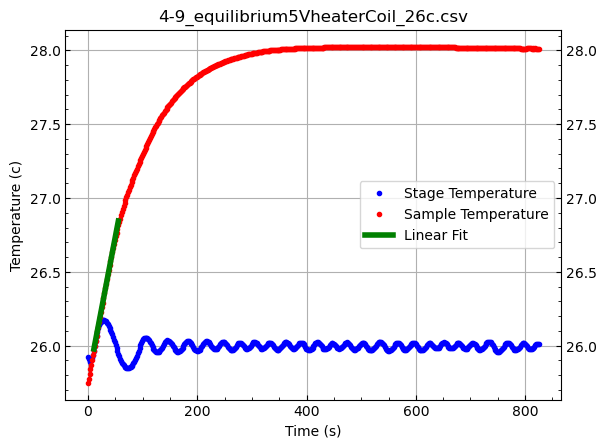

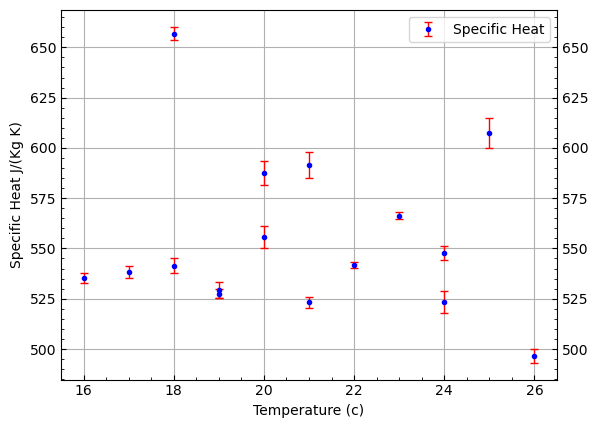

In [11]:
#raw strings with single backslashes or normal string with doublebackslashes which register as non escape characters
folder_path = r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\datalist'
filenames = os.listdir(folder_path)

#Get indeces that correspond to linear sections
indeces = np.array([(87,135),
                    (127,160),
                    (55,90),
                    (190,230),
                    (15,45),
                    (94,125),
                    (250,280),
                    (145,185),
                    (245,285),
                    (155,185),
                    (40,80), # 
                    (130,166),
                    (40,80),
                    (103,135),
                    (172,215),
                    (7,35)])

#no=15
#start = "C:\\Users\\Lawre\\OneDrive\\Desktop\\gadolinium\\datalist"
#file = filenames[no]
#end = "\\"+file
#totalFilePath = start+end
#plotFile(totalFilePath)
#plotFile(totalFilePath , indeces[no][0] , indeces[no][1])


def linear(x , a , b):
    return a*x + b


specificError = np.array([])
instantSpecificHeats = np.array([])
temperaturesOrdered = np.array([18,19,20,21,22,23,24,25,16,17,18,19,20,21,24,26])
power = 5*(5/200) # 5V * 5V/200 OHMS  =  V^2/R

count=0
for file in filenames:
    start = "C:\\Users\\Lawre\\OneDrive\\Desktop\\gadolinium\\datalist"
    end = "\\" + file
    totalFilePath = start+end
    #Do some linear fitting on each one and then print the information below
    tempTime , tempStage , tempSample = loadnsave(totalFilePath)
    
    vals , pcov = scipy.optimize.curve_fit(linear , tempTime[indeces[count][0]:indeces[count][1]] , tempSample[indeces[count][0]:indeces[count][1]])
    instantSpecificHeats = np.append(instantSpecificHeats, (1/0.013)*(power/vals[0])) 

    aTerm = np.sqrt( np.diag(pcov)[0] ) * (1/0.013)*(power / (vals[0]**2))
    massTerm = 0.01*(1/0.013)*(power/vals[0])*(1/0.013)**2
    specificError = np.append(specificError , np.sqrt( aTerm**2  )  ) #derivative wrt error * error in slope
    

    fitLineX = np.linspace( tempTime[indeces[count][0]] , tempTime[indeces[count][1]] , 100) 
    fitLineY = linear( fitLineX , vals[0] , vals[1])
    
    #Starting Index 100 ending index 150, if none passed then it just plots everything
    plotFile(totalFilePath)
    plt.plot( fitLineX , fitLineY ,color="green",label="Linear Fit",linewidth=4) 
    plt.legend()

    #USE THIS ONE FOR WHEN YOU WANT TO SEE ALL OF THE LINEAR REGIONS
    #plotFile(totalFilePath , indeces[count][0],indeces[count][1]) 
    count = count + 1

fig = plt.figure()
ax = fig.add_subplot()
plt.errorbar(temperaturesOrdered[:] , instantSpecificHeats[:], yerr=specificError[:] ,
             fmt='o',
             markersize=3,
             color='blue',
             ecolor='red',
             elinewidth=1,
             capsize=3,
             capthick=1,
             label="Specific Heat")
plotStandards("Temperature (c)", "Specific Heat J/(Kg K)")

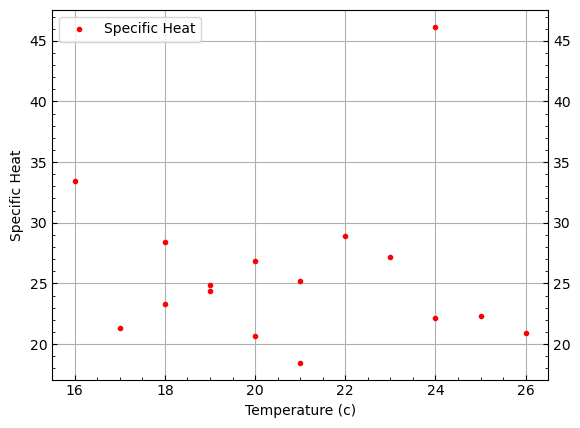

In [171]:
def tempOfTime(t , B, D,C):
    P= 25/200 #Watts
    
    return  C - np.exp(-B*t+D)

folder_path = r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\datalist'
filenames = os.listdir(folder_path)

#for the curved fitting we just use the starting indices no need to use the final one since all of it is useful
indeces = np.array([(87,135),
                    (127,160),
                    (55,90),
                    (190,230),
                    (15,45),
                    (94,125),
                    (250,280),
                    (145,185),
                    (245,285),
                    (155,185),
                    (40,80), # 
                    (130,166),
                    (40,80),
                    (103,135),
                    (172,215),
                    (7,35)])
count = 0


temperaturesOrdered = np.array([18,19,20,21,22,23,24,25,16,17,18,19,20,21,24,26])
bVals = np.array([])
cVals = np.array([])


for file in filenames:
    startingIndex = indeces[count][0]
    
    start = "C:\\Users\\Lawre\\OneDrive\\Desktop\\gadolinium\\datalist"
    end = "\\" + file
    totalFilePath = start+end
    #Do some curve fitting on each one and then print the information below
    tempTime , tempStage , tempSample = loadnsave(totalFilePath)
    
    vals , pcov = scipy.optimize.curve_fit( tempOfTime ,  tempTime[startingIndex:] , tempSample[startingIndex:],p0=[0.012,2.5,20])
    
    #print( file , vals , np.sqrt(np.diag(pcov)) )
    
    x = np.linspace( tempTime[startingIndex] , tempTime[len(tempTime)-1] )
    y = tempOfTime( x , vals[0] , vals[1],vals[2])
     
    
    #plotFile(totalFilePath, startingIndex , len(tempTime))
    #plt.plot(x,y,label="Curve Fit")

    bVals = np.append(bVals, vals[0])
    cVals = np.append(cVals , vals[2]) 
    
    count = count + 1


#MAKE CHANGES TO THE B VALUES BECAUSE THEY ARE NOT INHERENTLY SPECIFIC HEATS 
aList = (25/200)*(cVals - temperaturesOrdered ) #cvals - baseTemperature
specificHeats = aList / bVals
fig = plt.figure()
ax = fig.add_subplot()
plt.plot(temperaturesOrdered , specificHeats , "." ,color="red",  label="Specific Heat")
plotStandards("Temperature (c)" , "Specific Heat")